# Poisson Noise Experiment — Analysis

Analyzes a completed `poisson-noise` run (see
[docs/poisson_noise_experiment.md](../docs/poisson_noise_experiment.md) for the
experiment design). Reads the raw `poisson_results.jsonl` directly (not just
the pre-aggregated `poisson_stratum_summary.csv`) so we can break out trends
by `wavelength_angstrom`, which the stratum-summary aggregation does not
group by.

Trends covered:
1. By scene type (`quiet_sun`, `active_region`, `flare`, `flare_saturated`)
2. By wavelength (94–335 Å)
3. Between the two error metrics (`sqrt_dn` vs `aiapy_estimate_error`)
4. Between regions (`full`, `on_disk`, `off_disk`)
5. Before vs. after BID deconvolution


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import pandas as pd
from aiapy.calibrate import estimate_error

pd.set_option("display.width", 120)

# Point this at any completed poisson-noise run directory.
RUN_DIR = Path("/Users/arobbert/__SOC_CODE__/SDAC/runs/20260928T200652Z_89ca204d")

with (RUN_DIR / "poisson_results.jsonl").open() as f:
    results = pd.DataFrame(json.loads(line) for line in f if line.strip())

scene_type_order = ["quiet_sun", "active_region", "flare", "flare_saturated"]
results["scene_type"] = pd.Categorical(
    results["scene_type"], categories=scene_type_order, ordered=True
)
results["region"] = pd.Categorical(
    results["region"], categories=["full", "on_disk", "off_disk"], ordered=True
)
results["stage"] = pd.Categorical(
    results["stage"], categories=["before", "after"], ordered=True
)

print(
    f"run_id={results['run_id'].iloc[0]}  rows={len(results)}  images={results['image_id'].nunique()}"
)
results.head()

/opt/miniconda3/envs/sdac/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


run_id=20260928T200652Z_89ca204d  rows=924  images=77


,config_hash,count,fraction_ge_0p5dn,image_id,max,mean,median,metric,min,p05,p95,q1,q3,region,run_id,scene_id,scene_type,stage,std,wavelength_angstrom
0,d10cc952ceb9916088beffcfee0aa336962b8b8db9f4c6...,16777216,0.650678,active_20120708_ar11520__0094A,56.258333,1.176375,1.000000,sqrt_dn,0.000000,0.000000,3.162278,0.000000,1.732051,full,20260928T200652Z_89ca204d,active_20120708_ar11520,active_region,before,1.250991,94
1,d10cc952ceb9916088beffcfee0aa336962b8b8db9f4c6...,7771520,0.799973,active_20120708_ar11520__0094A,56.258333,1.578695,1.414214,sqrt_dn,0.000000,0.000000,3.605551,1.000000,2.000000,on_disk,20260928T200652Z_89ca204d,active_20120708_ar11520,active_region,before,1.347673,94
2,d10cc952ceb9916088beffcfee0aa336962b8b8db9f4c6...,9005696,0.521842,active_20120708_ar11520__0094A,30.016662,0.829190,1.000000,sqrt_dn,0.000000,0.000000,2.645751,0.000000,1.414214,off_disk,20260928T200652Z_89ca204d,active_20120708_ar11520,active_region,before,1.043049,94
3,d10cc952ceb9916088beffcfee0aa336962b8b8db9f4c6...,14164250,1.000000,active_20120708_ar11520__0094A,79.129004,2.468718,2.316319,aiapy_estimate_error,1.189678,1.189678,4.810440,1.841286,3.052103,full,20260928T200652Z_89ca204d,active_20120708_ar11520,active_region,before,1.490498,94
4,d10cc952ceb9916088beffcfee0aa336962b8b8db9f4c6...,7175509,1.000000,active_20120708_ar11520__0094A,79.129004,2.809707,2.709305,aiapy_estimate_error,1.189678,1.189678,5.391227,1.841286,3.360109,on_disk,20260928T200652Z_89ca204d,active_20120708_ar11520,active_region,before,1.655505,94


## 1. Trends by scene type

Headline stratum: on-disk, **pre-deconvolution** (`region="on_disk"`,
`stage="before"`) — the primary stratum for the design doc's decision
criteria. Pre-deconvolution carries more statistical rigor than
post-deconvolution, since deconvolution itself alters pixel statistics in
ways neither error metric models. Post-deconvolution figures are reported
only as a comparison, in section 5.



fraction_ge_0p5dn                           mean          
metric          aiapy_estimate_error   sqrt_dn aiapy_estimate_error   sqrt_dn
scene_type                                                                   
quiet_sun                        1.0  0.930901             6.161575  5.758519
active_region                    1.0  0.966913             8.972276  8.797511
flare                            1.0  0.919278             6.811968  6.556240
flare_saturated                  1.0  0.879868             6.549312  6.087786

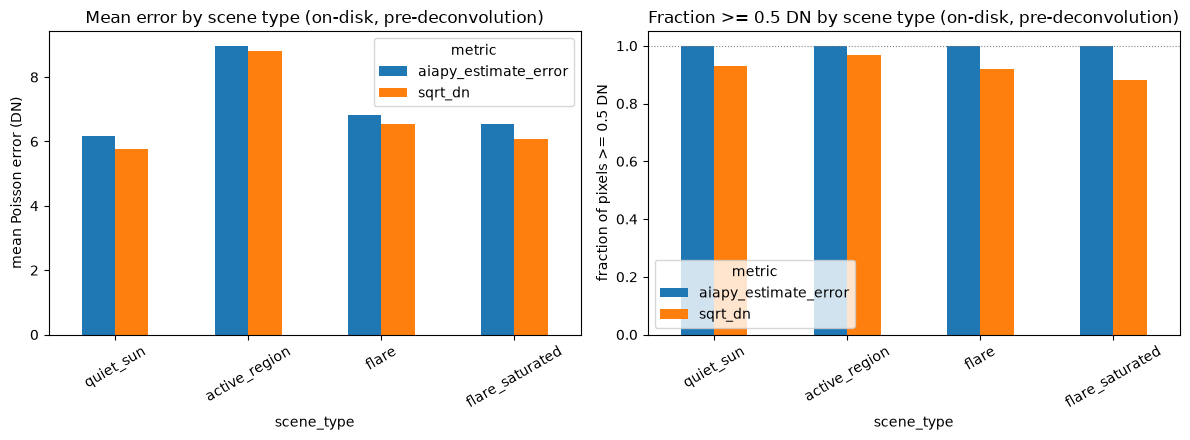

In [2]:
headline = results[(results["region"] == "on_disk") & (results["stage"] == "before")]
by_scene = headline.pivot_table(
    index="scene_type",
    columns="metric",
    values=["mean", "fraction_ge_0p5dn"],
    observed=False,
)
display(by_scene)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
by_scene["mean"].plot.bar(ax=axes[0], rot=30)
axes[0].set_ylabel("mean Poisson error (DN)")
axes[0].set_title("Mean error by scene type (on-disk, pre-deconvolution)")
axes[0].legend(title="metric")

by_scene["fraction_ge_0p5dn"].plot.bar(ax=axes[1], rot=30)
axes[1].axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
axes[1].set_ylabel("fraction of pixels >= 0.5 DN")
axes[1].set_title("Fraction >= 0.5 DN by scene type (on-disk, pre-deconvolution)")
axes[1].legend(title="metric")
fig.tight_layout()
plt.show()

## 2. Trends by wavelength

`poisson_stratum_summary.csv` doesn't group by wavelength, so this uses the
raw `poisson_results.jsonl` directly. Same headline stratum (on-disk,
pre-deconvolution).



fraction_ge_0p5dn                           mean           
metric              aiapy_estimate_error   sqrt_dn aiapy_estimate_error    sqrt_dn
wavelength_angstrom                                                               
94                                   1.0  0.859714             2.731195   1.570978
131                                  1.0  0.899420             3.826625   2.852139
171                                  1.0  0.999999            16.214969  15.222037
193                                  1.0  0.924184            12.742160  12.732129
211                                  1.0  0.999732             8.877763   9.305818
304                                  1.0  0.999078             3.888757   4.648134
335                                  1.0  0.815787             1.950584   1.722101

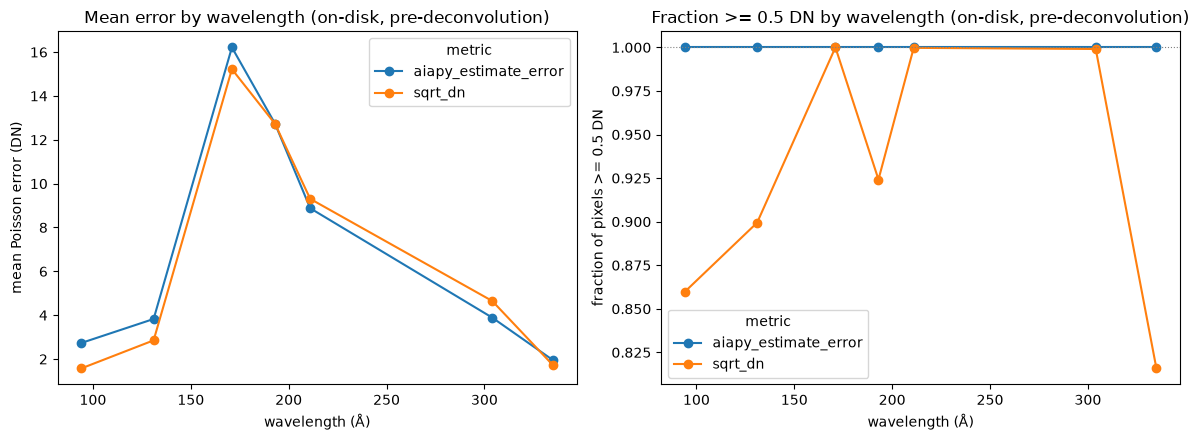

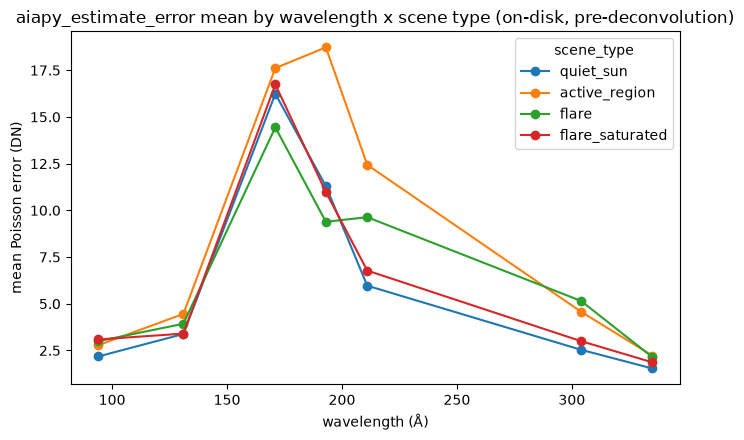

In [3]:
by_wavelength = headline.pivot_table(
    index="wavelength_angstrom",
    columns="metric",
    values=["mean", "fraction_ge_0p5dn"],
    observed=False,
)
display(by_wavelength)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
by_wavelength["mean"].plot(ax=axes[0], marker="o")
axes[0].set_xlabel("wavelength (Å)")
axes[0].set_ylabel("mean Poisson error (DN)")
axes[0].set_title("Mean error by wavelength (on-disk, pre-deconvolution)")

by_wavelength["fraction_ge_0p5dn"].plot(ax=axes[1], marker="o")
axes[1].axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
axes[1].set_xlabel("wavelength (Å)")
axes[1].set_ylabel("fraction of pixels >= 0.5 DN")
axes[1].set_title("Fraction >= 0.5 DN by wavelength (on-disk, pre-deconvolution)")
fig.tight_layout()
plt.show()

# Same, but split out by scene type to see whether the wavelength trend holds
# within each scene class or is driven by a subset of it.
by_wavelength_scene = headline[
    headline["metric"] == "aiapy_estimate_error"
].pivot_table(
    index="wavelength_angstrom", columns="scene_type", values="mean", observed=False
)
by_wavelength_scene.plot(
    marker="o",
    figsize=(7, 4.5),
    title="aiapy_estimate_error mean by wavelength x scene type (on-disk, pre-deconvolution)",
)
plt.xlabel("wavelength (Å)")
plt.ylabel("mean Poisson error (DN)")
plt.tight_layout()
plt.show()

## 3. Comparing the two error metrics

`sqrt_dn` is the naive literal-DN heuristic; `aiapy_estimate_error` is the
gain-corrected estimate. Per the physics in the design doc,
`aiapy_estimate_error` should be consistently >= `sqrt_dn` (since $Y/g > 1$
for AIA). Restricted to the primary pre-deconvolution, on-disk headline
stratum (77 images).



Rows where aiapy_estimate_error < sqrt_dn (on-disk, pre-deconvolution):
35 / 77

ratio_aiapy_over_sqrt describe():
count    77.000000
mean      1.240743
std       0.443029
min       0.797476
25%       0.955790
50%       1.064615
75%       1.388769
max       3.100221
Name: ratio_aiapy_over_sqrt, dtype: float64


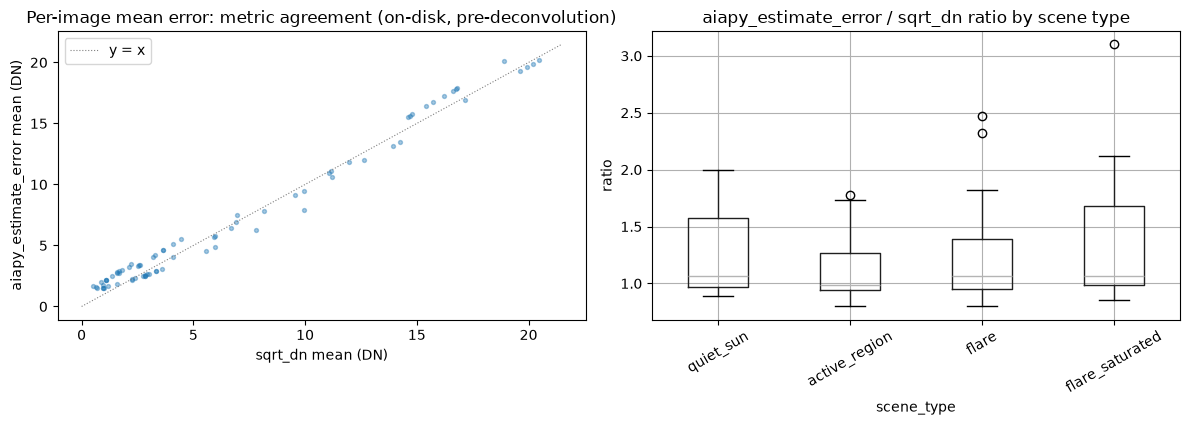

In [4]:
paired = headline.pivot_table(
    index=["image_id", "scene_type", "wavelength_angstrom"],
    columns="metric",
    values="mean",
    observed=False,
).reset_index()
paired["ratio_aiapy_over_sqrt"] = paired["aiapy_estimate_error"] / paired["sqrt_dn"]

print("Rows where aiapy_estimate_error < sqrt_dn (on-disk, pre-deconvolution):")
print((paired["aiapy_estimate_error"] < paired["sqrt_dn"]).sum(), "/", len(paired))
print()
print("ratio_aiapy_over_sqrt describe():")
print(paired["ratio_aiapy_over_sqrt"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
lims = [0, paired[["aiapy_estimate_error", "sqrt_dn"]].to_numpy().max() * 1.05]
axes[0].scatter(paired["sqrt_dn"], paired["aiapy_estimate_error"], s=8, alpha=0.4)
axes[0].plot(lims, lims, color="grey", linewidth=0.8, linestyle=":", label="y = x")
axes[0].set_xlabel("sqrt_dn mean (DN)")
axes[0].set_ylabel("aiapy_estimate_error mean (DN)")
axes[0].set_title("Per-image mean error: metric agreement (on-disk, pre-deconvolution)")
axes[0].legend()

paired.boxplot(column="ratio_aiapy_over_sqrt", by="scene_type", ax=axes[1], rot=30)
axes[1].set_title("aiapy_estimate_error / sqrt_dn ratio by scene type")
axes[1].set_ylabel("ratio")
plt.suptitle("")
fig.tight_layout()
plt.show()

## 4. Trends by region (full vs. on-disk vs. off-disk)

`on_disk` and `off_disk` partition `full`; comparing them shows how much the
disk/limb geometry mask matters vs. just using the full frame.
Pre-deconvolution (`stage="before"`), the primary stratum.



fraction_ge_0p5dn                           mean          
metric                   aiapy_estimate_error   sqrt_dn aiapy_estimate_error   sqrt_dn
scene_type      region                                                                
quiet_sun       full                      1.0  0.787199             4.672975  3.986059
                on_disk                   1.0  0.930901             6.161575  5.758519
                off_disk                  1.0  0.653261             3.178359  2.332435
active_region   full                      1.0  0.855554             6.757626  6.260476
                on_disk                   1.0  0.966913             8.972276  8.797511
                off_disk                  1.0  0.754463             4.639966  3.967188
flare           full                      1.0  0.815672             5.157220  4.602926
                on_disk                   1.0  0.919278             6.811968  6.556240
                off_disk                  1.0  0.719350             3.499341  2.761810
flare_saturated full                      1.0  0.767044             4.949030  4.252923
                on_disk                   1.0  0.879868             6.549312  6.087786
                off_disk                  1.0  0.667098             3.444031  2.626733

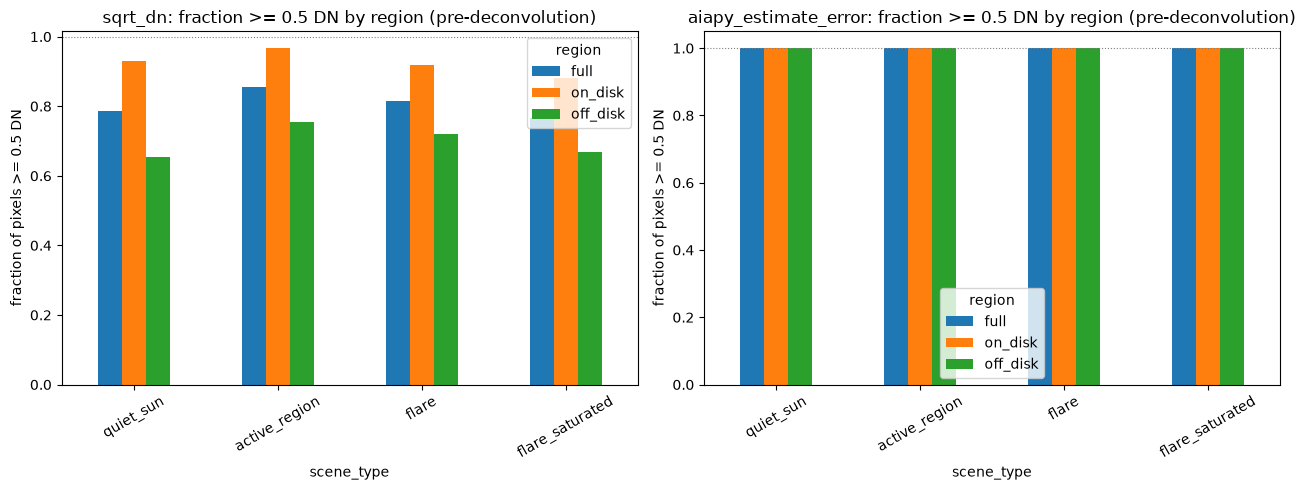

In [5]:
before = results[results["stage"] == "before"]
by_region = before.pivot_table(
    index=["scene_type", "region"],
    columns="metric",
    values=["mean", "fraction_ge_0p5dn"],
    observed=False,
)
display(by_region)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["sqrt_dn", "aiapy_estimate_error"]):
    pivot = before[before["metric"] == metric].pivot_table(
        index="scene_type", columns="region", values="fraction_ge_0p5dn", observed=False
    )
    pivot.plot.bar(ax=ax, rot=30)
    ax.axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
    ax.set_ylabel("fraction of pixels >= 0.5 DN")
    ax.set_title(f"{metric}: fraction >= 0.5 DN by region (pre-deconvolution)")
    ax.legend(title="region")
fig.tight_layout()
plt.show()

## 5. Comparison: pre- vs. post-deconvolution (on-disk)

Does deconvolution meaningfully change the Poisson error floor established
above? Headline region again (on-disk). Shown as boxplots of the per-image
distribution (grouped by scene type and stage) rather than bars of the
mean, so the full spread is visible, not just the central tendency.



fraction_ge_0p5dn                           mean          
metric                 aiapy_estimate_error   sqrt_dn aiapy_estimate_error   sqrt_dn
scene_type      stage                                                               
quiet_sun       before                  1.0  0.930901             6.161575  5.758519
                after                   1.0  0.874489             6.228682  5.808692
active_region   before                  1.0  0.966913             8.972276  8.797511
                after                   1.0  0.919216             8.986162  8.785229
flare           before                  1.0  0.919278             6.811968  6.556240
                after                   1.0  0.858771             6.694748  6.422267
flare_saturated before                  1.0  0.879868             6.549312  6.087786
                after                   1.0  0.821732             6.433679  5.963911

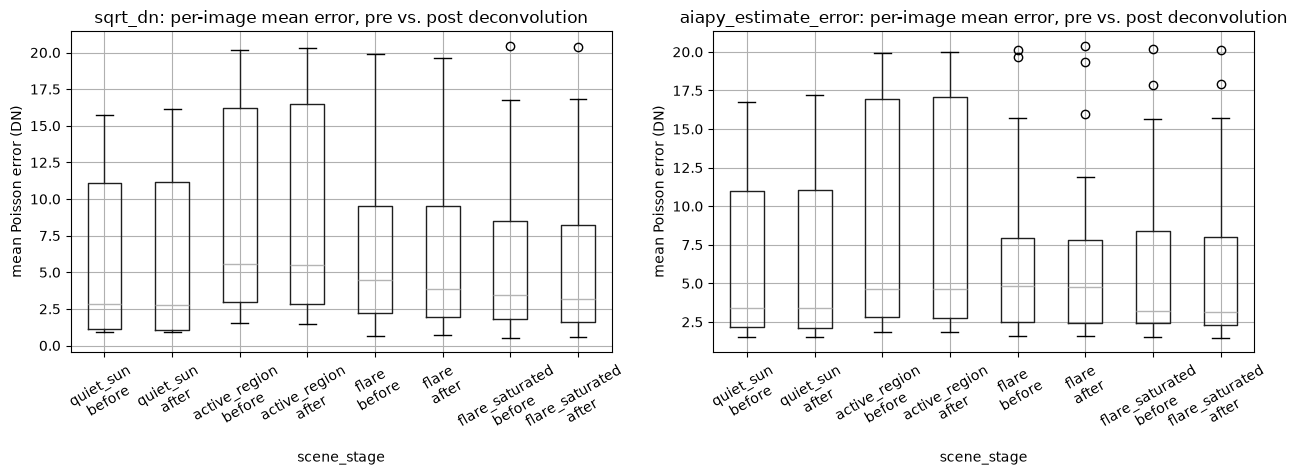

Percent change in mean/fraction, after vs. before (on-disk):


fraction_ge_0p5dn                           mean          
metric          aiapy_estimate_error   sqrt_dn aiapy_estimate_error   sqrt_dn
scene_type                                                                   
quiet_sun                        0.0 -6.059866             1.089131  0.871278
active_region                    0.0 -4.932829             0.154760 -0.139617
flare                            0.0 -6.581987            -1.720792 -2.043450
flare_saturated                  0.0 -6.607409            -1.765585 -2.034825

In [6]:
on_disk = results[results["region"] == "on_disk"]
by_stage = on_disk.pivot_table(
    index=["scene_type", "stage"],
    columns="metric",
    values=["mean", "fraction_ge_0p5dn"],
    observed=False,
)
display(by_stage)

stage_order = ["before", "after"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["sqrt_dn", "aiapy_estimate_error"]):
    sub = on_disk[on_disk["metric"] == metric].copy()
    sub["scene_stage"] = pd.Categorical(
        sub["scene_type"].astype(str) + "\n" + sub["stage"].astype(str),
        categories=[f"{s}\n{stg}" for s in scene_type_order for stg in stage_order],
        ordered=True,
    )
    sub.boxplot(column="mean", by="scene_stage", ax=ax, rot=30)
    ax.set_ylabel("mean Poisson error (DN)")
    ax.set_title(f"{metric}: per-image mean error, pre vs. post deconvolution")
plt.suptitle("")
fig.tight_layout()
plt.show()

# Percent change, after vs before, per scene type / metric
pct_change = (
    (by_stage.xs("after", level="stage") - by_stage.xs("before", level="stage"))
    / by_stage.xs("before", level="stage")
    * 100
)
print("Percent change in mean/fraction, after vs. before (on-disk):")
display(pct_change)

## 6. Headline decision-criteria table

The exact figure the design doc's decision criteria calls for: fraction of
on-disk, pre-deconvolution pixels with Poisson error >= 0.5 DN, by scene
type and metric.



In [7]:
headline_table = headline.pivot_table(
    index="scene_type", columns="metric", values="fraction_ge_0p5dn", observed=False
)
headline_table["n_images"] = headline.groupby("scene_type", observed=False)[
    "image_id"
].nunique()
display(headline_table)

metric,aiapy_estimate_error,sqrt_dn,n_images
scene_type,,,
quiet_sun,1.0,0.930901,21
active_region,1.0,0.966913,21
flare,1.0,0.919278,21
flare_saturated,1.0,0.879868,14


## 7. Why is `aiapy_estimate_error`'s fraction always exactly 1.0?

Every stratum above shows `fraction_ge_0p5dn == 1.0` for `aiapy_estimate_error`,
regardless of scene type, wavelength, region, or stage — even `quiet_sun`
`off_disk` `before`. That's suspicious enough to check directly: is
`aiapy.calibrate.estimate_error`'s minimum possible output already above
0.5 DN, independent of the input DN count? Checked for every wavelength used
in this experiment, not just one.



In [8]:
aiapy_rows = results[results["metric"] == "aiapy_estimate_error"]
print("Distinct 'min' values observed across all 924 aiapy_estimate_error rows:")
print(aiapy_rows["min"].round(6).value_counts())

# Confirm directly against a zero-count pixel, independent of the pipeline,
# for every wavelength used in this experiment.
zero_dn_by_wavelength = pd.DataFrame(
    [
        {
            "wavelength_angstrom": int(wl),
            "estimate_error_at_0_dn": float(
                estimate_error(0 * u.DN / u.pix, wl * u.angstrom).value[0]
            ),
        }
        for wl in sorted(results["wavelength_angstrom"].unique())
    ]
).set_index("wavelength_angstrom")
print("\nestimate_error(0 DN) by wavelength (DN/pix), independent of scene data:")
display(zero_dn_by_wavelength)

Distinct 'min' values observed across all 924 aiapy_estimate_error rows:
min
1.228061    132
1.189678    129
1.247290    117
1.199264     55
5.842358      2
6.859116      2
2.523040      2
2.440437      2
1.560684      2
5.545351      1
5.325996      1
4.886536      1
3.860341      1
3.227109      1
6.306362      1
3.082418      1
4.651261      1
5.938060      1
4.964245      1
4.560234      1
4.453508      1
2.706979      1
2.614524      1
3.604960      1
1.820916      1
1.964519      1
3.059139      1
1.423493      1
Name: count, dtype: int64

estimate_error(0 DN) by wavelength (DN/pix), independent of scene data:


,estimate_error_at_0_dn
wavelength_angstrom,
94,1.189678
131,1.228061
171,1.199264
193,1.247290
211,1.247290
304,1.189678
335,1.228061
